In [7]:
# Experiment to test the performance of different IP forward models from MPA and Cole  

import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np
import torch

from anemone.experiment import *
from anemone.forwards import *
from anemone.inversion import SmoothModelColeCole, FewLayerColeCole

In [8]:
tx = Loop.square(3)
rx = Receiver(x=13)
waveform = Waveform.example()
recfilter = FilterChain([ButterworthFilter(2.4e5,1),
                         ButterworthFilter(6.2e5,1),
                         ButterworthFilter(4.5e5,1)])

In [9]:
times = torch.logspace(-5,-3, 32)
fwrTD = Forward(tx, rx,times,filterfunc=recfilter, waveform=waveform)



frqs = torch.logspace(3, 6, 51)
fwrFD = ForwardFD(tx,rx, frqs, filterfunc=recfilter)

In [10]:
second_layer_rhos = torch.tensor([1000, 100, 10], dtype=torch.double)
Thickness = torch.tensor([30], dtype= torch.double)


rho_values= torch.logspace(start=torch.log10(torch.tensor(10)), end=torch.log10(torch.tensor(1000)), steps=11, dtype=torch.double)

cmap = cm.get_cmap('rainbow')
norm = mcolors.Normalize(vmin=float(rho_values.min()), vmax=float(rho_values.max()))
sm = cm.ScalarMappable(cmap=cmap, norm=norm)

C:\Users\au653994\AppData\Local\Temp\ipykernel_3048\4282793349.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('rainbow')


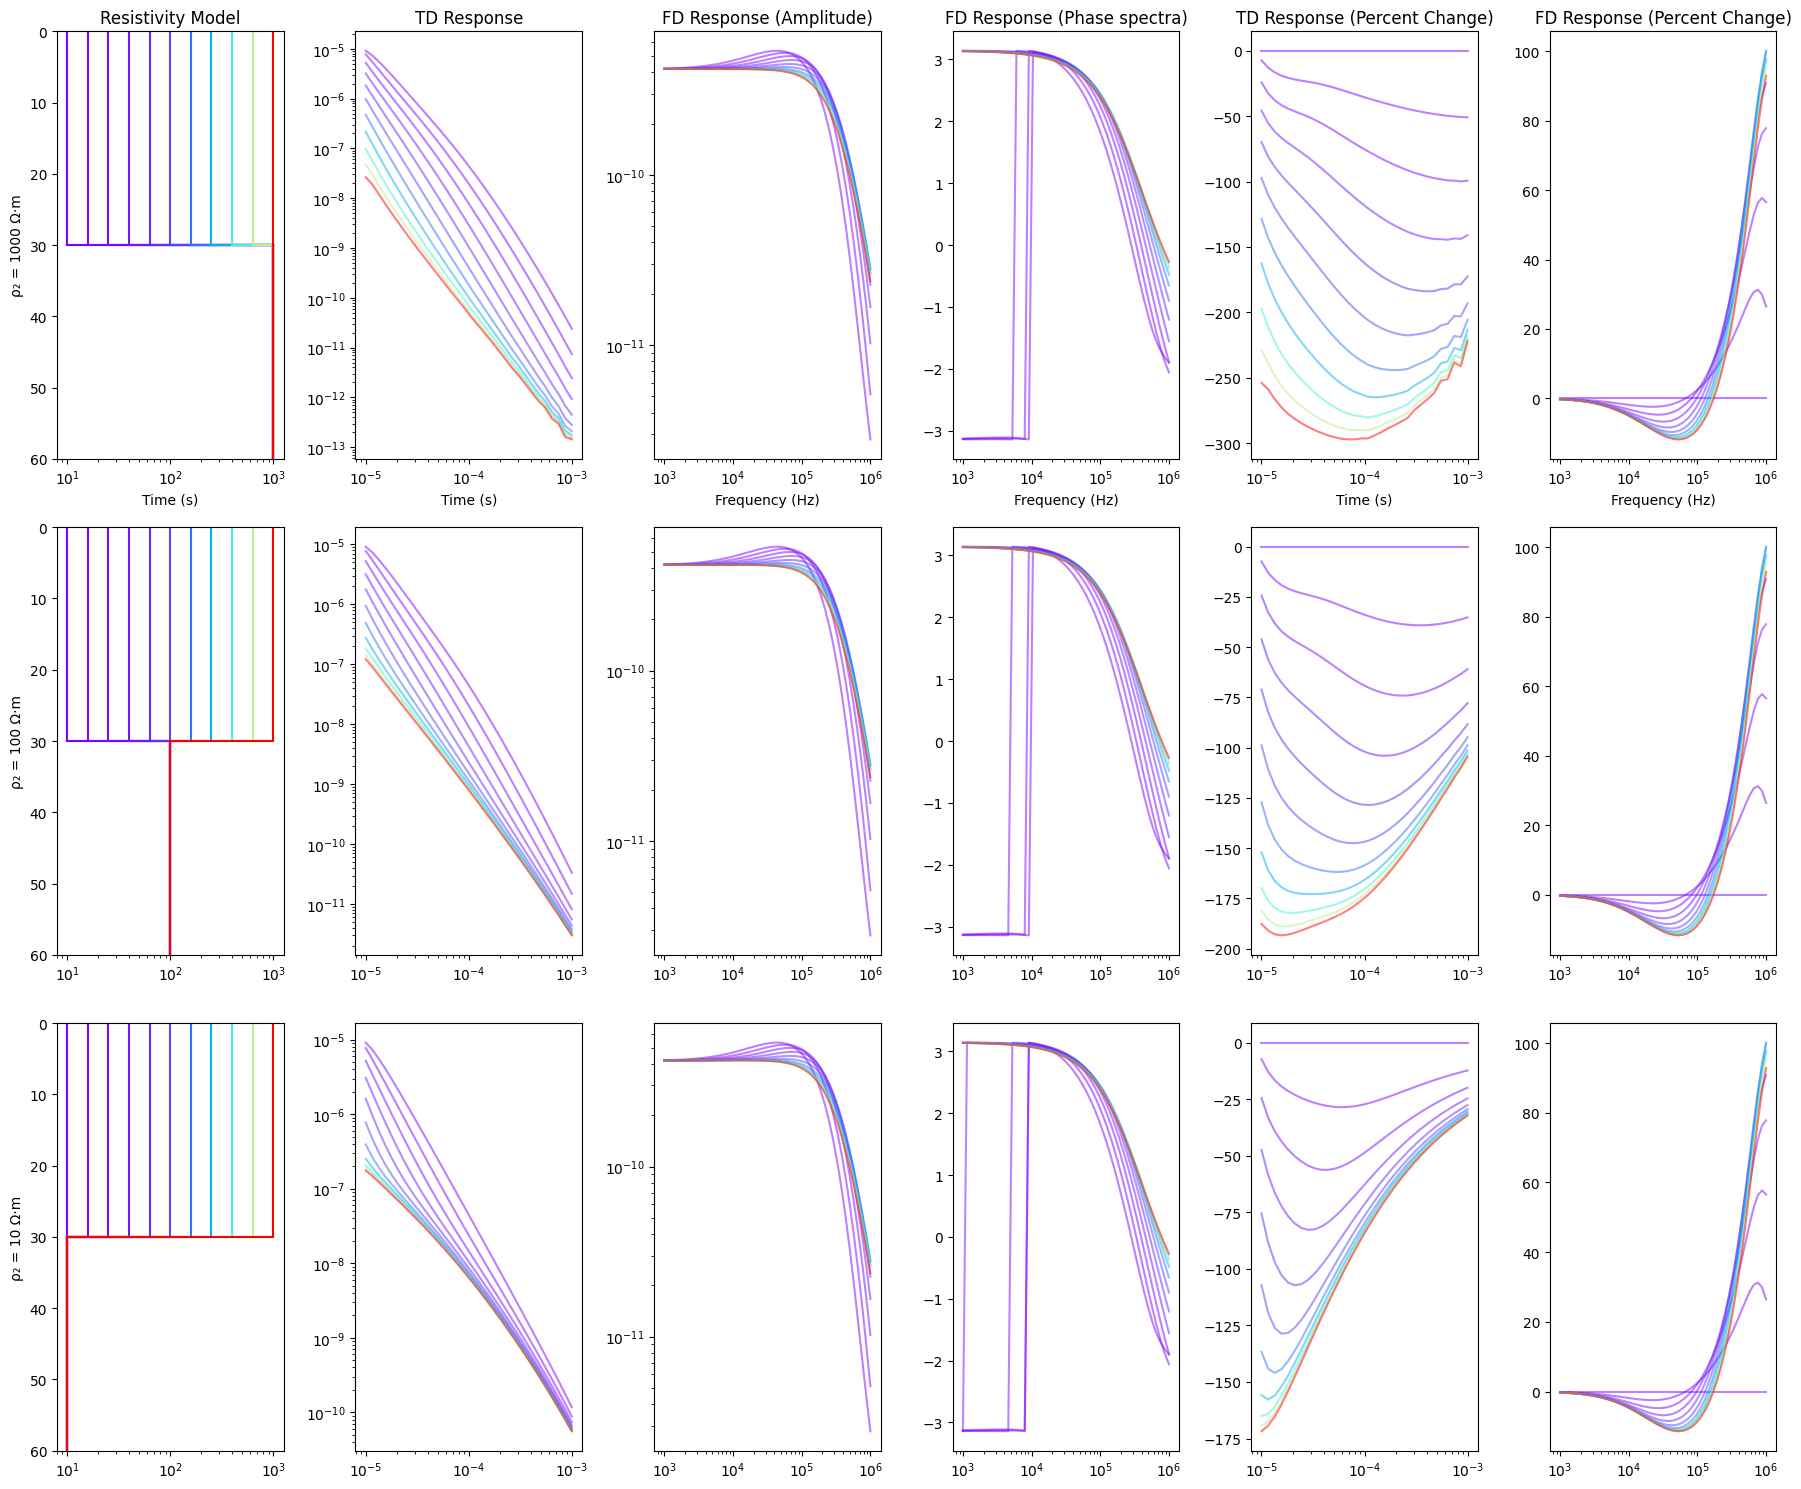

In [11]:
z0 = 0.0
z1 = Thickness[0].item()
z2 = 100.0 # Bottom truncation 

n_models = len(second_layer_rhos)

fig, axs = plt.subplots(n_models,6, figsize=(18, 5*n_models))

for i, rho2 in enumerate(second_layer_rhos):

    rho_ref= torch.tensor([rho_values[0].item(), rho2.item()], dtype=torch.double)
    #rho_ref= torch.tensor([rho2.item(), rho_values[0].item()], dtype=torch.double) # First layer fixed

    dbdt_ref = fwrTD(rho_ref, Thickness)
    dbdf_ref = fwrFD(rho_ref, Thickness)

    for rho0 in rho_values:

        color = cmap(norm(rho0.item()))

        rho = torch.tensor([rho0.item(), rho2.item()], dtype=torch.double)
        #rho = torch.tensor([ rho2.item(), rho0.item()], dtype=torch.double) # First layer fixed

        dbdt = fwrTD(rho, Thickness)
        dbdf = fwrFD(rho, Thickness)


        axs[i, 1].loglog(times, dbdt, color=color, linestyle = '-',alpha=0.5)
        axs[i, 1].plot(times, -dbdt, color=color, linestyle = '-',alpha=0.5)
        axs[i, 2].loglog(frqs,torch.abs( dbdf), color=color, linestyle = '-', alpha=0.5)

        axs[i,3].semilogx(frqs, torch.angle(dbdf), color=color, linestyle = '-', alpha=0.5)
        
        #pct_change_dbdt = ((dbdt - dbdt_ref) / dbdt_ref) * 100
        #pct_change_dbdf = ((dbdf - dbdf_ref) / dbdf_ref) * 100

        pct_change_dbdt = 100 * (torch.log10(torch.abs(dbdt)) - torch.log10(torch.abs(dbdt_ref)))
        pct_change_dbdf = 100 * (torch.log10(torch.abs(dbdf)) - torch.log10(torch.abs(dbdf_ref)))


        axs[i,4].semilogx(times, pct_change_dbdt, color=color, linestyle = '-', alpha=0.5)
        axs[i,5].semilogx(frqs, pct_change_dbdf, color=color, linestyle = '-', alpha=0.5)

        # Plot the reference model 

        axs[i,0].semilogx([rho[0].item(), rho[0].item()], [z0, z1], color=color, linestyle='-')
        axs[i,0].semilogx([rho[0].item(), rho[1].item()], [z1, z1], color=color, linestyle='-')
        axs[i,0].semilogx([rho[1].item(), rho[1].item()], [z1, z2], color=color, linestyle='-')
        axs[i,0].invert_yaxis()
        #axs[i,0].set_xlim(1e0, 2e3)
        axs[i,0].set_ylim(60, 0)
        axs[i,0].set_ylabel('Depth (m)')


axs[0,0].set_title('Resistivity Model')
axs[0,1].set_title('TD Response')
axs[0,2].set_title('FD Response (Amplitude)')
axs[0,3].set_title('FD Response (Phase spectra)')
axs[0,4].set_title('TD Response (Percent Change)')
axs[0,5].set_title('FD Response (Percent Change)')


axs[0][0].set_xlabel('Time (s)')
axs[0][1].set_xlabel('Time (s)')
axs[0][2].set_xlabel('Frequency (Hz)')
axs[0][3].set_xlabel('Frequency (Hz)')
axs[0][4].set_xlabel('Time (s)')
axs[0][5].set_xlabel('Frequency (Hz)')

savefig = True
plt.tight_layout()


axs[0][0].set_ylabel(f'ρ₂ = 1000 Ω·m')
axs[1][0].set_ylabel(f'ρ₂ = 100 Ω·m')
axs[2][0].set_ylabel(f'ρ₂ = 10 Ω·m')

if savefig:
    plt.savefig(r'c:\Users\au653994\OneDrive - Aarhus universitet\Documents\PhD\anemone\Figures\2L_IP_Var\Res_Loop_Second_L_Fixed.png', dpi=300, bbox_inches='tight')


plt.show()

In [12]:
log_ratio_percent = 100 * (np.log10(15/10))